# Modelling with an Atmospheric Chemistry Model: GEOS-Chem

In [1]:
# Import packages that we'll use as part fo the analysis

import xarray as xa
import numpy as np
import cartopy
import matplotlib
import matplotlib.pyplot as plt


In [2]:
# load the data file for GEOSChem model

# Define filepath
GEOSChem_file = '~/Documents/geog0121/data/UKESM1_model_output/additional_files/GEOSChem.SpeciesConc.20210701_0000z.nc4'

# Open datasets
GEOSChem_data = xa.open_dataset(GEOSChem_file)


In [3]:
print(GEOSChem_data)

<xarray.Dataset> Size: 232MB
Dimensions:                 (lat: 46, nb: 2, lon: 72, lev: 47, ilev: 48, time: 1)
Coordinates:
  * time                    (time) datetime64[ns] 8B 2021-07-01
  * lev                     (lev) float64 376B 0.9925 0.9775 ... 3.8e-05
  * ilev                    (ilev) float64 384B 1.0 0.985 0.97 ... 6.6e-05 1e-05
  * lat                     (lat) float64 368B -89.0 -86.0 -82.0 ... 86.0 89.0
  * lon                     (lon) float64 576B -180.0 -175.0 ... 170.0 175.0
Dimensions without coordinates: nb
Data variables: (12/381)
    lat_bnds                (lat, nb) float64 736B ...
    lon_bnds                (lon, nb) float64 1kB ...
    hyam                    (lev) float64 376B ...
    hybm                    (lev) float64 376B ...
    hyai                    (ilev) float64 384B ...
    hybi                    (ilev) float64 384B ...
    ...                      ...
    SpeciesConcVV_ALK4      (time, lev, lat, lon) float32 623kB ...
    SpeciesConcVV_ALD2    

In [4]:
# Define variables of interest from GEOSChem file

# Concentration of hydrophillic black carbon species
GC_BCPI = GEOSChem_data.SpeciesConcVV_BCPI
# Concentration of hydrophobic black carbon species
GC_BCPO = GEOSChem_data.SpeciesConcVV_BCPO
# Sum of black carbon species
GC_BC = GC_BCPI + GC_BCPO

# Concentration of hydrophillic organic aerosols
GC_OCPI = GEOSChem_data.SpeciesConcVV_OCPI
# Concentration of hydrophobic organic aerosols
GC_OCPO = GEOSChem_data.SpeciesConcVV_OCPO

# Concentration of sulphate
GC_SO4 = GEOSChem_data.SpeciesConcVV_SO4


# Dimensions too
latitude = GEOSChem_data.lat
longitude = GEOSChem_data.lon
level = GEOSChem_data.lev

# Add attributes to calculated fields
GC_BC.attrs["long_name"] = "Concentration of Black Carbon"

In [5]:
print(GC_SO4)

<xarray.DataArray 'SpeciesConcVV_SO4' (time: 1, lev: 47, lat: 46, lon: 72)> Size: 623kB
[155664 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 8B 2021-07-01
  * lev      (lev) float64 376B 0.9925 0.9775 0.9625 ... 0.0001387 3.8e-05
  * lat      (lat) float64 368B -89.0 -86.0 -82.0 -78.0 ... 78.0 82.0 86.0 89.0
  * lon      (lon) float64 576B -180.0 -175.0 -170.0 ... 165.0 170.0 175.0
Attributes:
    long_name:         Concentration of species SO4
    units:             mol mol-1 dry
    averaging_method:  time-averaged


# Choose pressure level to create a global map of an above species

The GEOS-Chem model has dimensions of atmospheric level (height in pressure), latitude and longitude. We can explore the lat, lon distributions of the pollutants at different pressure levels.

In [6]:
# Level Choice
target_level = 'surface' # 'surface' for surface, pressure in hybrid sigma coordinates.For target_level not equal to 'surface', target_level should be between 1 (surface) and 0 (top of atmosphere). 0.85 is therefore very ~ 850 hPa and 0.5 ~ 500 hPa

# Pollutant Choice
pchoice = GC_SO4

In [7]:
# Loop to assign which atmospheric level to map at:
if target_level == 'surface':
    pidx = 0
else:
    pidx = np.abs(level - target_level).argmin().values

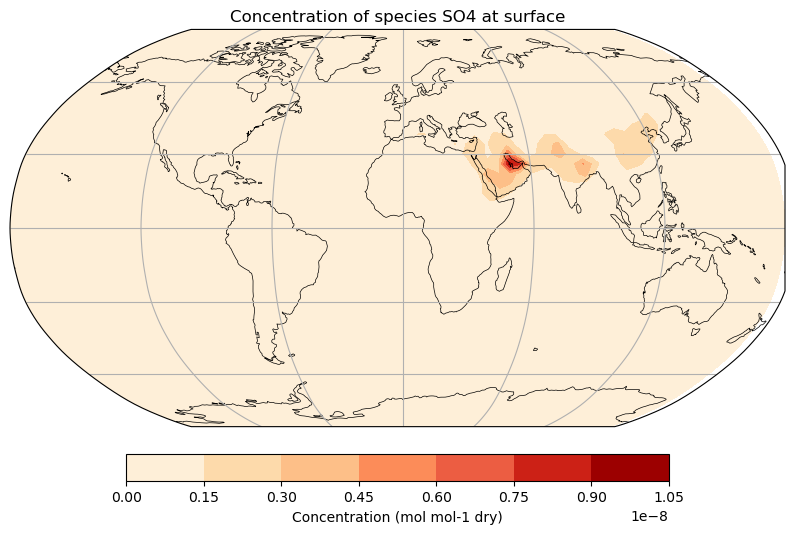

In [8]:
# Create map figure using choices from Choice Cell

plt.figure(figsize=(10,7))
ax = plt.axes(projection=cartopy.crs.Robinson())

ax.coastlines(resolution='110m', linewidth=0.5)
ax.gridlines()
ax.set_title(f'{pchoice.long_name} at {target_level}')
fig=ax.contourf(longitude,latitude,pchoice[0, pidx, :, :],transform=cartopy.crs.PlateCarree(),cmap='OrRd')
cax,kw = matplotlib.colorbar.make_axes(ax,location='bottom',pad=0.05,shrink=0.7)
cbar = plt.colorbar(fig,cax=cax,extend='both',**kw)
cbar.set_label(f'Concentration ({GC_BCPI.units})')

# Vertical Profiles

Use a coordinate pair (lat, lon) to view a vertical profile of the pollutant in the atmosphere

In [9]:
# First select coordinates
Coords = [52, 0] # Coordinate pair near London

In [10]:
# Loop to find coordinate indices closest to chosen coords
# define target lat and lon
tlat, tlon = Coords
# Find nearest latitude index (use values to convert to integer)
lat_idx = np.abs(latitude - tlat).argmin().values
# find nearest longitude index
lon_idx = np.abs(longitude - tlon).argmin().values


Text(0.5, 1.0, 'Atmospheric profile of Black Carbon')

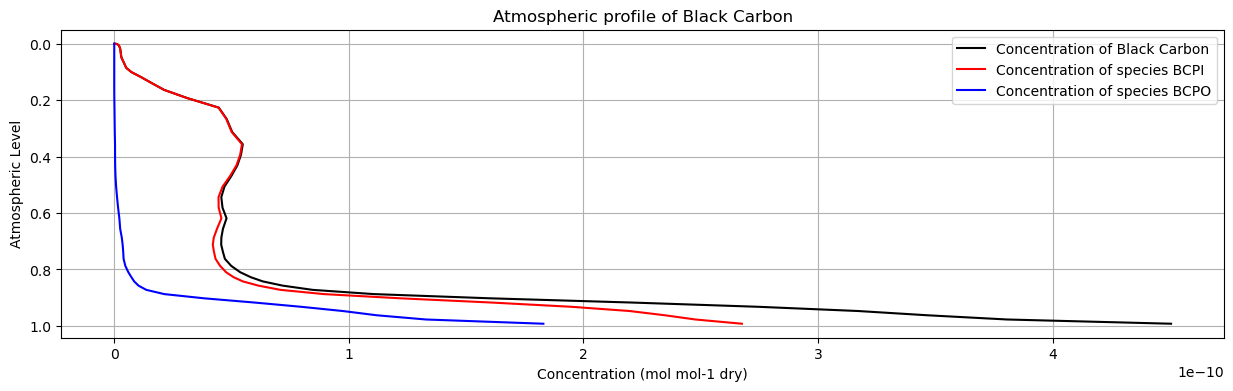

In [11]:
# Create a atmospheric profile of pollutants
fig, ax = plt.subplots(figsize=(15,4))
ax.plot(GC_BC[0, :, lat_idx, lon_idx], level, label =f'{GC_BC.long_name}', color = 'black')
ax.plot(GC_BCPI[0, :, lat_idx, lon_idx], level, label=f'{GC_BCPI.long_name}',color='red')
ax.plot(GC_BCPO[0, :, lat_idx, lon_idx], level, label =f'{GC_BCPO.long_name}', color = 'blue')
ax.grid()
ax.invert_yaxis()
ax.legend(loc='best') 
ax.set(xlabel=f'Concentration ({GC_BCPI.units})',ylabel='Atmospheric Level')
ax.set_title(f'Atmospheric profile of Black Carbon')

# Compare to UKESM1-0-LL Output

It can be interesting to compare the output of two models to look for differences in pattern and why they appear.

Often when we compare between two models that have not been co-ordinated by the same groups, we have to perform additional data processing steps such that comparison between the two models is more useful.

The atmospheric chemistry variables for UKESM are load variables, which means that the concentration of thes pollutants has been column integrated over the whole atmosphere, leaving one vertical level of data. To compare GEOS-Chem output to UKESM we must also column integrate the GEOS-Chem output, to do this we need additional data about the atmosphere and a new GEOS-Chem file.

In addition, in UKESM the atmospheric chemistry variables are not standard output and have only been produced as part of some experiments. The future scenarios are not included in this subset currently. So we use the historical simulation (which covers up until the end of 2014).

In [12]:
# Define filepaths to UKESM files
UKESM_BC_file = '~/Documents/geog0121/data/UKESM1_model_output/additional_files/loadbc_Emon_UKESM1-0-LL_historical_r1i1p1f2_gn_195001-201412.nc'
UKESM_OA_file = '~/Documents/geog0121/data/UKESM1_model_output/additional_files/loadoa_Emon_UKESM1-0-LL_historical_r1i1p1f2_gn_195001-201412.nc'
UKESM_SO4_file = '~/Documents/geog0121/data/UKESM1_model_output/additional_files/loadso4_Emon_UKESM1-0-LL_historical_r1i1p1f2_gn_195001-201412.nc'

# Define filepath
# Added height dat
GEOSChem_metfile = '~/Documents/geog0121/data/UKESM1_model_output/additional_files/GEOSChem.StateMet.20210701_0000z.nc4'

# Open files
UKESM_BC = xa.open_dataset(UKESM_BC_file)
UKESM_OA = xa.open_dataset(UKESM_OA_file)
UKESM_SO4 = xa.open_dataset(UKESM_SO4_file)
GEOSChem_met = xa.open_dataset(GEOSChem_metfile)

In [13]:
# Select suitable date for comparison from UKESM variables

# Pick out July 2014
UKESM_BC_dt = UKESM_BC.loadbc.sel(time="2014-07")
UKESM_OA_dt = UKESM_OA.loadoa.sel(time="2014-07")
UKESM_SO4_dt = UKESM_SO4.loadso4.sel(time="2014-07")

In [14]:
# Column integrate our GEOS-Chem variables to be comparable to UKESM

# Define layer height and air density variables
GC_BXHeight = GEOSChem_met.Met_BXHEIGHT
GC_AirDen = GEOSChem_met.Met_AIRDEN

# Apply a scaling factor to OCPI and OCPO to get approximation for OA
GC_OA = (1.5* GC_OCPO) + (2.1* GC_OCPI)

# Define a function to column integrate our pollutants
def column_int(data, species):
    # set value for molecular weight of species
    if species == 'BC':
        # measured in g/mol. Need to convert to kg/mol.
        mw = 12.01/1000
    elif species == 'OA':
        mw = 12.01/1000
    elif species == 'SO4':
        mw = 96.04/1000
    else:
        raise ValueError("Unknown species passed to function")
    # same as above but for air
    mw_air = 28.97/1000
    return(data * GC_AirDen * GC_BXHeight * mw * 1/(mw_air)).sum(dim='lev')

# Apply function
# We use only atmospheric levels up to and including level 44 to avoid levels close to the top of atmosphere boundary
GC_BC_col = column_int(GC_BC[:, 0:45, :, :], 'BC')
GC_OA_col = column_int(GC_OA[:, 0:45, :, :], 'OA')
GC_SO4_col = column_int(GC_SO4[:, 0:45, :, :], 'SO4')


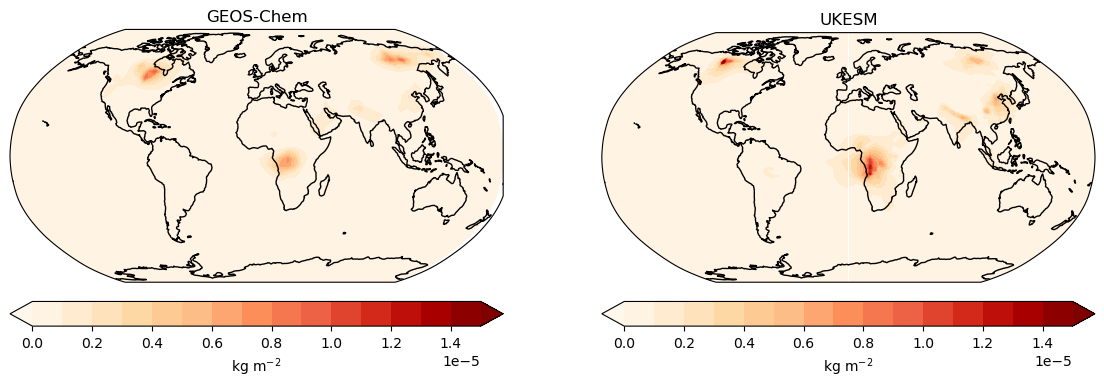

In [15]:
levs = np.linspace(0, 1.5e-5, 16)

# Lets plot a quick comparison between the two models
fig, axs = plt.subplots(1, 2, figsize = (14, 5), subplot_kw={'projection': cartopy.crs.Robinson()})
# Panel 1: GEOS-Chem
cf1 = axs[0].contourf(longitude, latitude, GC_BC_col[0, :, :], levels = levs, cmap='OrRd', extend = 'both', transform = cartopy.crs.PlateCarree())
axs[0].coastlines()
axs[0].set_title("GEOS-Chem")
# Panel 2: UKESM
cf2 = axs[1].contourf(UKESM_BC_dt.lon, UKESM_BC_dt.lat, UKESM_BC_dt[0, :, :], levels = levs, cmap='OrRd', extend = 'both', transform = cartopy.crs.PlateCarree())
axs[1].coastlines()
axs[1].set_title("UKESM")
# Separate colorbars
cbar1 = fig.colorbar(cf1, ax=axs[0], orientation='horizontal', pad=0.05)
cbar1.set_label("kg m$^{-2}$")
cbar2 = fig.colorbar(cf2, ax=axs[1], orientation='horizontal', pad=0.05)
cbar2.set_label("kg m$^{-2}$")
plt.show()